## 1.0 Import libraries and load the dataset

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading the dataset
df = pd.read_csv('Dataset_ATS_v2.csv')
df.head()

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
0,Female,0,No,1,No,No,DSL,Month-to-month,25,Yes
1,Male,0,No,41,Yes,No,DSL,One year,25,No
2,Female,0,Yes,52,Yes,No,DSL,Month-to-month,19,No
3,Female,0,No,1,Yes,No,DSL,One year,76,Yes
4,Male,0,No,67,Yes,No,Fiber optic,Month-to-month,51,No


## 2.0 Explore the data

In [6]:
# Shape and structure
print("Shape:", df.shape)
df.info()

Shape: (7043, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   gender           7043 non-null   object
 1   SeniorCitizen    7043 non-null   int64 
 2   Dependents       7043 non-null   object
 3   tenure           7043 non-null   int64 
 4   PhoneService     7043 non-null   object
 5   MultipleLines    7043 non-null   object
 6   InternetService  7043 non-null   object
 7   Contract         7043 non-null   object
 8   MonthlyCharges   7043 non-null   int64 
 9   Churn            7043 non-null   object
dtypes: int64(3), object(7)
memory usage: 550.4+ KB


In [7]:
# Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
gender             0
SeniorCitizen      0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
Contract           0
MonthlyCharges     0
Churn              0
dtype: int64


In [8]:
# Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 302


In [9]:
# Summary statistics for numeric columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.758768
std,0.368612,24.559481,30.091650
min,0.000000,0.000000,18.000000
25%,0.000000,9.000000,36.000000
50%,0.000000,29.000000,70.000000
75%,0.000000,55.000000,90.000000
max,1.000000,72.000000,119.000000


In [10]:
# Look at unique values in each categorical column
categorical_cols = ['gender', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'Contract', 'Churn']
for col in categorical_cols:
    print(col, ":", df[col].unique())

gender : ['Female' 'Male']
Dependents : ['No' 'Yes']
PhoneService : ['No' 'Yes']
MultipleLines : ['No' 'Yes']
InternetService : ['DSL' 'Fiber optic']
Contract : ['Month-to-month' 'One year' 'Two year']
Churn : ['Yes' 'No']


No     5174
Yes    1869
Name: Churn, dtype: int64
No     73.463013
Yes    26.536987
Name: Churn, dtype: float64


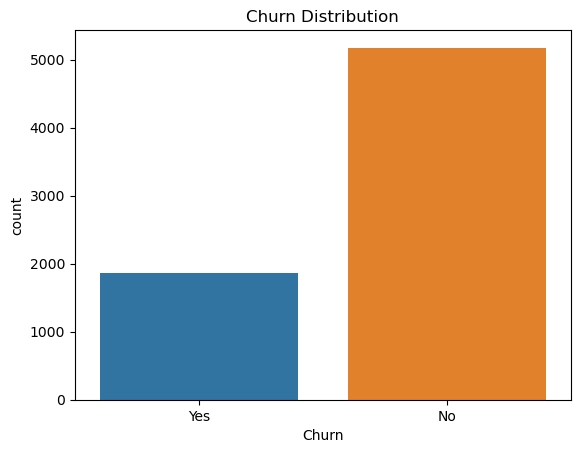

In [11]:
# Target variable balance
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True) * 100)

sns.countplot(data=df, x='Churn')
plt.title('Churn Distribution')
plt.show()

### Initial Data Exploration Notes

We checked the dataset before doing anything else. There are no missing values, so the cleaning step for this dataset will be light. We did find 302 duplicate rows, so we will drop those in the next step.

We also looked at the target variable. Churn is imbalanced, with around 73% No and 27% Yes. We are noting this now because it will affect how we read the model's accuracy later. A model could score high on accuracy just by predicting "No" most of the time, so we will need to look at precision and recall too, not just accuracy, when we evaluate the ANN.

## 3.0 Clean the data

In [13]:
# Drop duplicate rows
print("Rows before dropping duplicates:", df.shape[0])
df = df.drop_duplicates()
print("Rows after dropping duplicates:", df.shape[0])

# Reset index after dropping rows
df = df.reset_index(drop=True)

# Double check there are no missing values left
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Rows before dropping duplicates: 7043
Rows after dropping duplicates: 6741

Missing values after cleaning:
gender             0
SeniorCitizen      0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
Contract           0
MonthlyCharges     0
Churn              0
dtype: int64


## 4.0 Encode categorical variables

In [14]:
from sklearn.preprocessing import LabelEncoder

# Copy the dataframe so the original stays untouched
df_encoded = df.copy()

# Binary columns to label encode
binary_cols = ['gender', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'Churn']

le = LabelEncoder()
for col in binary_cols:
    df_encoded[col] = le.fit_transform(df_encoded[col])
    print(col, "classes:", list(le.classes_))

gender classes: ['Female', 'Male']
Dependents classes: ['No', 'Yes']
PhoneService classes: ['No', 'Yes']
MultipleLines classes: ['No', 'Yes']
InternetService classes: ['DSL', 'Fiber optic']
Churn classes: ['No', 'Yes']


In [15]:
# One-hot encode Contract, since it has more than two categories
df_encoded = pd.get_dummies(df_encoded, columns=['Contract'], drop_first=True)

df_encoded.head()

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,MonthlyCharges,Churn,Contract_One year,Contract_Two year
0,0,0,0,1,0,0,0,25,1,0,0
1,1,0,0,41,1,0,0,25,0,1,0
2,0,0,1,52,1,0,0,19,0,0,0
3,0,0,0,1,1,0,0,76,1,1,0
4,1,0,0,67,1,0,1,51,0,0,0


### Data Cleaning and Encoding Notes

We dropped the 302 duplicate rows we found earlier and reset the index so the dataframe stays clean going forward. There were no missing values to handle, so that part was straightforward.

For the categorical columns, we split them into two groups. Gender, Dependents, PhoneService, MultipleLines, InternetService, and Churn are all binary, so we label encoded those as 0 and 1. We printed the classes for each column so we know exactly which value maps to which label, since label encoding assigns 0 and 1 alphabetically and we did not want to guess.

Contract has three categories (Month-to-month, One year, Two year) with no natural order between them, so we one-hot encoded that column instead of label encoding it. This avoids implying a ranking that does not exist in the data.

## 5.0 Feature scaling

In [16]:
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

# Identify numeric columns that need scaling
numeric_cols = ['tenure', 'MonthlyCharges']

scaler = StandardScaler()
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

X.head()

,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,MonthlyCharges,Contract_One year,Contract_Two year
0,0,0,0,-1.312875,0,0,0,-1.376228,0,0
1,1,0,0,0.331038,1,0,0,-1.376228,1,0
2,0,0,1,0.783114,1,0,0,-1.578399,0,0
3,0,0,0,-1.312875,1,0,0,0.342225,1,0
4,1,0,0,1.399582,1,0,1,-0.500154,0,0


## 6.0 Train/test split

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("\nChurn distribution in training set:")
print(y_train.value_counts(normalize=True))
print("\nChurn distribution in testing set:")
print(y_test.value_counts(normalize=True))

Training set shape: (5392, 10)
Testing set shape: (1349, 10)

Churn distribution in training set:
0    0.734236
1    0.265764
Name: Churn, dtype: float64

Churn distribution in testing set:
0    0.734618
1    0.265382
Name: Churn, dtype: float64


### Feature Scaling and Train/Test Split Notes

We scaled the numeric columns, tenure and MonthlyCharges, using StandardScaler. SeniorCitizen was already 0/1 so it did not need scaling. We scaled these because we are training a neural network later, and features on very different ranges can slow down or destabilise how the network converges.

We then split the data into training and testing sets, using 80% for training and 20% for testing. We used stratify=y in the split so the churn ratio stays roughly the same in both sets. Since churn is imbalanced in the full dataset, we wanted to avoid ending up with a test set that has too few churn cases to evaluate the model properly.

## 7.0 Elbow method and K-Means clustering

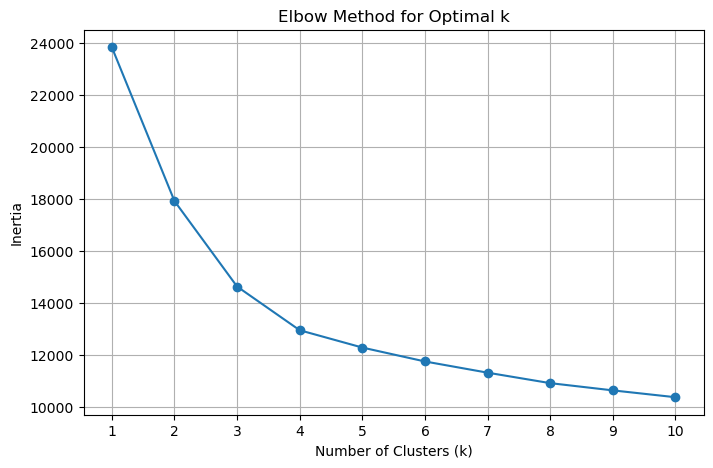

In [18]:
from sklearn.cluster import KMeans

# Use the scaled feature set for clustering
inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.xticks(k_range)
plt.grid(True)
plt.show()

Looking at the plot, the drop is steep from k=1 to k=3, then it flattens out noticeably from k=4 onward. The elbow sits around k=4, that's where adding more clusters stops giving much reduction in inertia. 

## 7.1 Train final K-Means model and visualise clusters

In [19]:
# Train the final K-Means model with the chosen k
optimal_k = 4
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X)

# Add the cluster labels back to a copy of the dataframe for interpretation
df_clustered = df_encoded.copy()
df_clustered['Cluster'] = cluster_labels

df_clustered['Cluster'].value_counts()

0    2149
2    1883
3    1585
1    1124
Name: Cluster, dtype: int64

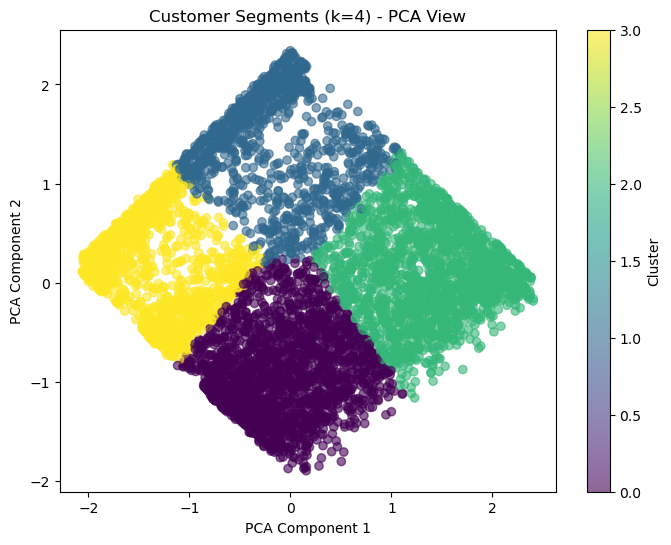

In [20]:
from sklearn.decomposition import PCA

# Reduce to 2 dimensions for visualisation only
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title(f'Customer Segments (k={optimal_k}) - PCA View')
plt.colorbar(scatter, label='Cluster')
plt.show()

In [21]:
# Interpret the clusters by looking at average feature values per cluster
cluster_summary = df_clustered.groupby('Cluster')[['tenure', 'MonthlyCharges', 'SeniorCitizen', 'Churn']].mean()
cluster_summary

,tenure,MonthlyCharges,SeniorCitizen,Churn
Cluster,,,,
0,15.195905,81.724058,0.243369,0.487669
1,54.333630,34.892349,0.077402,0.048043
2,58.714817,93.164100,0.215613,0.156134
3,11.227760,33.803785,0.071924,0.249211


### Clustering Notes

We used the elbow method to find the right number of clusters for K-Means. Looking at the inertia plot, the curve drops sharply up to around k=4, then flattens out, so we chose k=4 as the optimal number of clusters.

We trained the final K-Means model with k=4 and assigned each customer a cluster label. To visualise the clusters, we reduced the features to two dimensions using PCA, since we cannot plot the original feature space directly with more than two dimensions.

We also looked at the average tenure, monthly charges, senior citizen rate, and churn rate within each cluster. This let us describe each cluster in plain terms rather than just as a number, which will be useful when we bring these segments into the churn prediction discussion later.

### Cluster Interpretation Notes

We labelled the four clusters based on the average tenure, monthly charges, senior citizen rate, and churn rate within each group.

Cluster 0 stood out as high-risk new premium customers. They have low tenure, high monthly charges, and the highest churn rate of any cluster at nearly 49%. This group also has the highest proportion of senior citizens.

Cluster 1 represents loyal low-spend customers. They have long tenure, lower monthly charges, and the lowest churn rate at under 5%.

Cluster 2 represents loyal high-value customers, with the longest tenure and the highest monthly charges. Their churn rate is moderate at around 15.6%, which is notable given how much revenue this group represents.

Cluster 3 represents new low-spend customers. They have the shortest tenure and lower monthly charges, with a moderate-to-high churn rate of about 24.9%.

These labels will be useful later when we compare the ANN's churn predictions against these segments, since Cluster 0 in particular looks like the group retention strategies should prioritise.

## STAGE 2 DELIVERABLES

In [25]:
import os

# Create the folders that match the submission structure
os.makedirs('Data_Preparation', exist_ok=True)
os.makedirs('Clustering_Analysis', exist_ok=True)

In [24]:
# Save the cleaned and encoded dataset
df_encoded.to_csv('Data_Preparation/preprocessed_dataset.csv', index=False)

print("Saved. Rows:", df_encoded.shape[0], "Columns:", df_encoded.shape[1])

Saved. Rows: 6741 Columns: 11


### Stage 2 Repository Setup Notes

We created two folders, Data_Preparation and Clustering_Analysis, matching the structure required for the Stage 2 submission. This keeps the data preparation deliverables separate from the clustering deliverables, so they are easy for the instructor to find and review.

We saved the cleaned and encoded dataset as preprocessed_dataset.csv inside the Data_Preparation folder. This is the version of the data after we dropped duplicates, label encoded the binary columns, and one-hot encoded Contract. It has 6741  rows and 11 columns.

In [26]:
# Save the training and testing sets
X_train.to_csv('Data_Preparation/X_train.csv', index=False)
X_test.to_csv('Data_Preparation/X_test.csv', index=False)
y_train.to_csv('Data_Preparation/y_train.csv', index=False)
y_test.to_csv('Data_Preparation/y_test.csv', index=False)

print("Training set:", X_train.shape[0], "rows,", X_train.shape[1], "features")
print("Testing set:", X_test.shape[0], "rows,", X_test.shape[1], "features")
print("\nChurn distribution in training set:")
print(y_train.value_counts(normalize=True).round(3))
print("\nChurn distribution in testing set:")
print(y_test.value_counts(normalize=True).round(3))

Training set: 5392 rows, 10 features
Testing set: 1349 rows, 10 features

Churn distribution in training set:
0    0.734
1    0.266
Name: Churn, dtype: float64

Churn distribution in testing set:
0    0.735
1    0.265
Name: Churn, dtype: float64


### Training and Testing Set Notes

We saved the training and testing sets as separate CSV files inside the Data_Preparation folder, X_train.csv and X_test.csv for the features, and y_train.csv and y_test.csv for the target.

The training set has 5392 rows and the testing set has 1349 rows, an 80/20 split. We used stratify=y when splitting, so the churn ratio stayed close to 73.5% No and 26.5% Yes in both sets. This matters because churn is imbalanced in the full dataset, and stratifying avoids ending up with a test set that has too few churn cases to evaluate the model fairly.

## Save the trained K-Means model

In [28]:
import joblib

# Save the trained K-Means model so it can be reloaded without retraining
joblib.dump(kmeans_final, 'Clustering_Analysis/kmeans_model.pkl')

print("Model saved.")

Model saved.


In [29]:
# Quick check that the saved model loads and works correctly
loaded_model = joblib.load('Clustering_Analysis/kmeans_model.pkl')
print("Cluster centers shape:", loaded_model.cluster_centers_.shape)

Cluster centers shape: (4, 10)


### K-Means Model File Notes

We saved the trained K-Means model as kmeans_model.pkl inside the Clustering_Analysis folder, using joblib. This lets the model be reloaded later without retraining, and satisfies the Stage 2 requirement to include the trained model file alongside the clustering scripts.

We also reloaded the saved model to confirm it works correctly before including it in the submission.

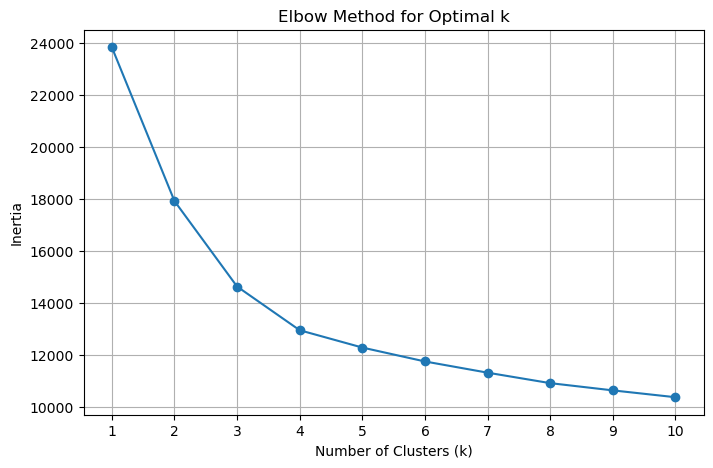

In [30]:
# Save the elbow plot as an image file for the documentation
plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.xticks(list(k_range))
plt.grid(True)
plt.savefig('Clustering_Analysis/elbow_method.png', dpi=150, bbox_inches='tight')
plt.show()

### Optimal Number of Clusters Notes

We saved the elbow method plot as elbow_method.png inside the Clustering_Analysis folder. This is the supporting visualisation for how we chose k=4 as the optimal number of clusters, showing a steep drop in inertia up to k=4 followed by a flattening curve.

## Save the cluster visualisation and labelled cluster summary

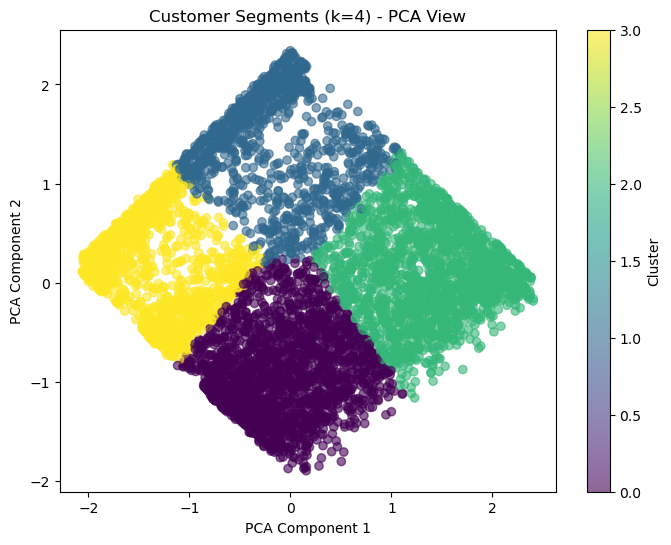

In [31]:
# Save the PCA cluster visualisation
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title(f'Customer Segments (k={optimal_k}) - PCA View')
plt.colorbar(scatter, label='Cluster')
plt.savefig('Clustering_Analysis/cluster_visualisation.png', dpi=150, bbox_inches='tight')
plt.show()

In [32]:
# Save the dataset with cluster labels attached
df_clustered.to_csv('Clustering_Analysis/clustered_dataset.csv', index=False)

# Save the cluster summary table (average feature values per cluster)
cluster_summary.to_csv('Clustering_Analysis/cluster_summary.csv')

print(cluster_summary)

            tenure  MonthlyCharges  SeniorCitizen     Churn
Cluster                                                    
0        15.195905       81.724058       0.243369  0.487669
1        54.333630       34.892349       0.077402  0.048043
2        58.714817       93.164100       0.215613  0.156134
3        11.227760       33.803785       0.071924  0.249211


In [33]:
# Map each cluster number to a plain-language label based on the averages
cluster_labels_map = {
    0: "High-risk new premium customers",
    1: "Loyal low-spend customers",
    2: "Loyal high-value customers",
    3: "New low-spend customers"
}
# Adjust the numbers above to match your own cluster_summary output

df_clustered['Cluster_Label'] = df_clustered['Cluster'].map(cluster_labels_map)
df_clustered.to_csv('Clustering_Analysis/clustered_dataset.csv', index=False)

df_clustered[['Cluster', 'Cluster_Label']].drop_duplicates().sort_values('Cluster')

,Cluster,Cluster_Label
3,0,High-risk new premium customers
1,1,Loyal low-spend customers
5,2,Loyal high-value customers
0,3,New low-spend customers


### Cluster Visualisation and Labelling Notes

We saved the PCA scatter plot as cluster_visualisation.png inside the Clustering_Analysis folder. Since the feature space has more than two dimensions, we used PCA to reduce it to two components purely for visualisation, so the four clusters could be plotted and inspected visually.

We also saved the clustered dataset (clustered_dataset.csv) and a summary table of average feature values per cluster (cluster_summary.csv). Based on tenure, monthly charges, senior citizen rate, and churn rate, we labelled the clusters in plain terms: high-risk new premium customers, loyal low-spend customers, loyal high-value customers, and new low-spend customers. These labels make the segments easier to interpret and will support the retention strategy recommendations later.